# Fase 3: Modelagem e Experimentos

Este notebook executa o pipeline de experimentação para previsão de risco criminal no entorno do IFSP-SPO, atendendo aos passos 1 a 7 do protocolo experimental da disciplina.

In [2]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

# Garantir que os diretórios de salvamento existam
os.makedirs("../models/checkpoints", exist_ok=True)
os.makedirs("../models/final", exist_ok=True)

sns.set_theme(style="whitegrid")

## 1. Carga e Preparação das Features
Vamos carregar a base unificada com a variável alvo (RISCO_ALTO) e extrair as features necessárias, aplicando One-Hot Encoding.

In [5]:
# Carregando dataset processado (substitua o caminho se necessário)
df = pd.read_csv("../data/processed/dados_processados.csv", sep=";")

# Garantir que DATA é datetime e extrair variáveis temporais
df["DATA"] = pd.to_datetime(df["DATA"])
df["MES"] = df["DATA"].dt.month
df["DIA_SEMANA"] = df["DATA"].dt.dayofweek
df["FLAG_FIM_DE_SEMANA"] = df["DIA_SEMANA"].isin([5, 6]).astype(int)

# Ordenar cronologicamente para garantir separação temporal correta
df = df.sort_values(["DATA"]).reset_index(drop=True)

# Definir matriz de Features (X) e Target (y)
features = ["MES", "DIA_SEMANA", "FLAG_FIM_DE_SEMANA"] + [
    col for col in df.columns if "PERIODO_" in col
]
X = df[features]
y = df["RISCO_ALTO"]

X.head()

,MES,DIA_SEMANA,FLAG_FIM_DE_SEMANA,PERIODO_MADRUGADA,PERIODO_MANHÃ,PERIODO_NOITE,PERIODO_TARDE
0,1,5,1,1,0,0,0
1,1,5,1,0,1,0,0
2,1,5,1,0,0,0,1
3,1,5,1,0,0,1,0
4,1,6,1,1,0,0,0


## 1. Separação Estrita do Conjunto de Teste
Separamos os ~15% finais dos dados chronologicamente para uso EXCLUSIVO no Passo 6 (avaliação de generalização).

In [6]:
# Partição cronológica (Sem usar train_test_split com shuffle)
split_idx = int(len(X) * 0.85)

X_dev, y_dev = (
    X.iloc[:split_idx],
    y.iloc[:split_idx],
)  # Desenvolvimento (Treino/Validação)
X_test, y_test = X.iloc[split_idx:], y.iloc[split_idx:]  # Teste Final

print(f"Tamanho Desenvolvimento: {len(X_dev)} instâncias")
print(f"Tamanho Teste Final: {len(X_test)} instâncias")

Tamanho Desenvolvimento: 5895 instâncias
Tamanho Teste Final: 1041 instâncias


## Passo 1 do Enunciado: Teste de Implementação (Sanity Check)
Verificação de consistência forçando overfitting num pequeno subconjunto para atestar a capacidade de convergência do modelo.

In [7]:
# Isolar 30 linhas
X_sanity, y_sanity = X_dev.iloc[:30], y_dev.iloc[:30]

# Treinar modelo não linear (Árvore de Decisão sem limite de profundidade)
modelo_sanity = DecisionTreeClassifier(random_state=42)
modelo_sanity.fit(X_sanity, y_sanity)

# Prever e calcular acurácia no próprio conjunto
y_pred_sanity = modelo_sanity.predict(X_sanity)
acc_sanity = accuracy_score(y_sanity, y_pred_sanity)

print(
    f"Acurácia no Teste de Sanidade (Overfitting proposital): {acc_sanity * 100:.2f}%"
)
assert acc_sanity > 0.95, (
    "Falha no teste de sanidade: Modelo não conseguiu decorar a amostra."
)
print("Implementação testada e validada.")

Acurácia no Teste de Sanidade (Overfitting proposital): 100.00%
Implementação testada e validada.


## Passos 3 e 4: Experimentação e Replicação (Múltiplas Sementes)
Vamos realizar a comparação entre Regressão Logística e Random Forest executando 30 iterações com particionamentos aleatórios estratificados no conjunto de desenvolvimento, salvando logs, pesos e gerando a amostra de erros.

In [8]:
n_iteracoes = 30
resultados = {"Modelo": [], "Seed": [], "F1_Score": [], "Acuracia": []}

for seed in range(42, 42 + n_iteracoes):
    # Variando o particionamento do conjunto de desenvolvimento (Validação Cruzada Monte Carlo)
    X_train, X_val, y_train, y_val = train_test_split(
        X_dev, y_dev, test_size=0.20, random_state=seed, stratify=y_dev
    )

    # Modelo 1: Regressão Logística
    lr = LogisticRegression(random_state=seed, max_iter=500)
    lr.fit(X_train, y_train)
    pred_lr = lr.predict(X_val)
    resultados["Modelo"].append("Logistic Regression")
    resultados["Seed"].append(seed)
    resultados["F1_Score"].append(f1_score(y_val, pred_lr))
    resultados["Acuracia"].append(accuracy_score(y_val, pred_lr))

    # Modelo 2: Random Forest
    rf = RandomForestClassifier(random_state=seed, n_estimators=100, max_depth=6)
    rf.fit(X_train, y_train)
    pred_rf = rf.predict(X_val)
    resultados["Modelo"].append("Random Forest")
    resultados["Seed"].append(seed)
    resultados["F1_Score"].append(f1_score(y_val, pred_rf))
    resultados["Acuracia"].append(accuracy_score(y_val, pred_rf))

    # Salvando pesos intermediários para reprodutibilidade
    joblib.dump(lr, f"../models/checkpoints/lr_seed_{seed}.pkl")
    joblib.dump(rf, f"../models/checkpoints/rf_seed_{seed}.pkl")

df_resultados = pd.DataFrame(resultados)
df_resultados.to_csv("../models/checkpoints/log_experimentos.csv", index=False)
print("Experimentos executados e resultados/pesos intermediários salvos com sucesso.")

Experimentos executados e resultados/pesos intermediários salvos com sucesso.


## Passo 5: Análise Estatística dos Resultados
Comparando as métricas obtidas e testando a significância estatística da diferença entre os dois modelos usando Teste-t pareado.

F1_Score            Acuracia          
                         mean       std      mean       std
Modelo                                                     
Logistic Regression  0.693284  0.010530  0.670144  0.011996
Random Forest        0.699926  0.013361  0.690444  0.013248

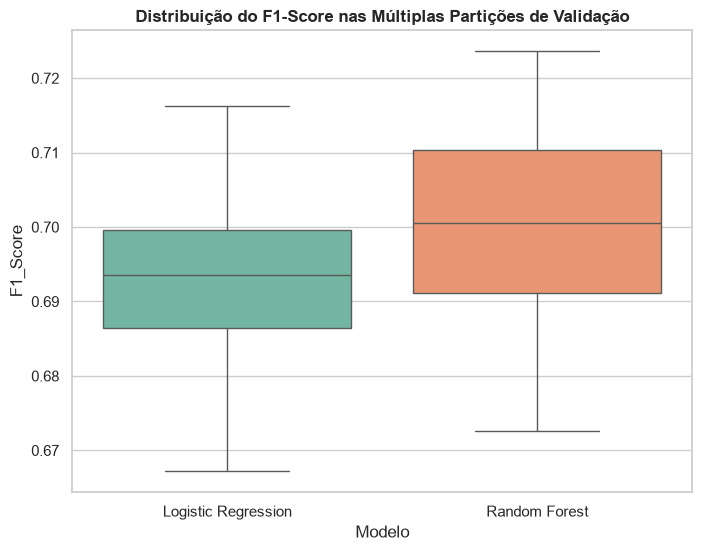

Teste de Shapiro-Wilk (p-valor): 0.9338
Diferenças assumem distribuição normal. Aplicando Teste-t Pareado...
Resultado do Teste de Hipótese (p-valor): 8.2406e-04
Há significância estatística! O modelo superior é: Random Forest


In [9]:
# Tabela descritiva
display(
    df_resultados.groupby("Modelo").agg(
        {"F1_Score": ["mean", "std"], "Acuracia": ["mean", "std"]}
    )
)

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=df_resultados, x="Modelo", y="F1_Score", palette="Set2", ax=ax)
ax.set_title(
    "Distribuição do F1-Score nas Múltiplas Partições de Validação", weight="bold"
)
plt.show()

# Teste t pareado
f1_lr = df_resultados[df_resultados["Modelo"] == "Logistic Regression"][
    "F1_Score"
].values
f1_rf = df_resultados[df_resultados["Modelo"] == "Random Forest"]["F1_Score"].values

# Verificando normalidade das diferenças
diferencas = f1_rf - f1_lr
stat_shapiro, p_shapiro = stats.shapiro(diferencas)

print(f"Teste de Shapiro-Wilk (p-valor): {p_shapiro:.4f}")
if p_shapiro > 0.05:
    print("Diferenças assumem distribuição normal. Aplicando Teste-t Pareado...")
    stat_teste, p_valor = stats.ttest_rel(f1_rf, f1_lr)
else:
    print("Diferenças NÃO são normais. Aplicando Teste de Wilcoxon...")
    stat_teste, p_valor = stats.wilcoxon(f1_rf, f1_lr)

print(f"Resultado do Teste de Hipótese (p-valor): {p_valor:.4e}")
if p_valor < 0.05:
    melhor_modelo = (
        "Random Forest" if f1_rf.mean() > f1_lr.mean() else "Logistic Regression"
    )
    print(f"Há significância estatística! O modelo superior é: {melhor_modelo}")
else:
    melhor_modelo = "Logistic Regression"  # Empate, escolhemos o mais simples
    print(
        "Não há diferença estatística. Adotaremos o modelo mais simples (Regressão Logística)."
    )

## Passo 6: Estimativa de Erro em Dados Não Vistos (Generalização)
Vamos treinar o modelo vencedor usando todo o conjunto de desenvolvimento e testar no conjunto X_test (que esteve intocado até agora).

=== RELATÓRIO FINAL DE GENERALIZAÇÃO ===
              precision    recall  f1-score   support

           0       0.91      0.58      0.71       802
           1       0.36      0.80      0.50       239

    accuracy                           0.63      1041
   macro avg       0.63      0.69      0.60      1041
weighted avg       0.78      0.63      0.66      1041



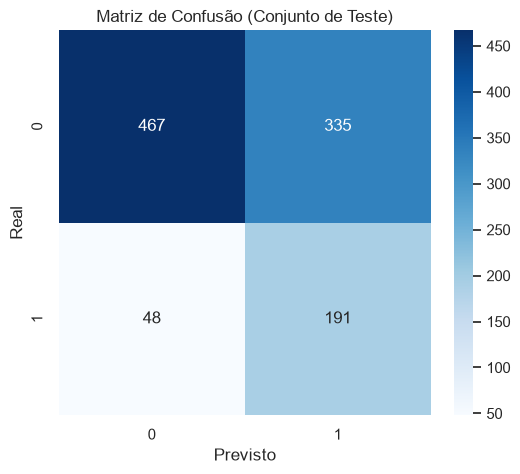

In [10]:
# Instancia modelo vencedor com os hiperparâmetros ajustados
if melhor_modelo == "Random Forest":
    modelo_val_final = RandomForestClassifier(
        random_state=42, n_estimators=100, max_depth=6
    )
else:
    modelo_val_final = LogisticRegression(random_state=42, max_iter=500)

# Treina no conjunto Dev inteiro
modelo_val_final.fit(X_dev, y_dev)

# Prever e avaliar no conjunto Teste Isolado
y_test_pred = modelo_val_final.predict(X_test)

print("=== RELATÓRIO FINAL DE GENERALIZAÇÃO ===")
print(classification_report(y_test, y_test_pred))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Matriz de Confusão (Conjunto de Teste)")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
plt.show()

## Passo 7: Treinamento da Versão Final
Treinamento do artefato final com todos os dados disponíveis (Dev + Test) para entrega/deploy. 

In [11]:
if melhor_modelo == "Random Forest":
    modelo_deploy = RandomForestClassifier(
        random_state=42, n_estimators=100, max_depth=6
    )
else:
    modelo_deploy = LogisticRegression(random_state=42, max_iter=500)

# Treina em TODO o dataset (X e y)
modelo_deploy.fit(X, y)

# Salva o arquivo final
caminho_final = "../models/final/modelo_risco_ifsp_final.joblib"
joblib.dump(modelo_deploy, caminho_final)

print(f"Artefato final treinado e salvo com sucesso em: {caminho_final}")

Artefato final treinado e salvo com sucesso em: ../models/final/modelo_risco_ifsp_final.joblib
